# TaxChronos: data report (Phase 1)

TaxChronos is a retrieval system over Pakistani tax law, so its dataset is a **text corpus**, not a table with a target column. The raw data is 12 official PDFs (statutes, rules, a rate card, manuals). The cleaned dataset is `data/processed/*.json`: one record per chunk of law, produced by `ingestion/parse.py`.

This notebook does three things:

1. **Cleaning audit**: checks the processed corpus for missing values, duplicates, outliers and inconsistent formats, and explains what the parser already cleaned.
2. **EDA**: size, balance, chunk lengths, amendment history and the evaluation set.
3. **Preprocessing**: what happens to a chunk before modeling, and why numeric scaling does not apply.

Run from the repo root or from `notebooks/`; it only reads files that are in the repo.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "sources.json").exists() else Path.cwd().parent
IMAGES = ROOT / "images"
IMAGES.mkdir(exist_ok=True)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
})

sources = pd.DataFrame(json.loads((ROOT / "sources.json").read_text(encoding="utf-8")))
df = pd.concat(
    [pd.DataFrame(json.loads(f.read_text(encoding="utf-8"))) for f in sorted((ROOT / "data/processed").glob("*.json"))],
    ignore_index=True,
)
df["chars"] = df["content"].str.len()
df["n_amendments"] = df["amendments"].str.len()
df["superseded"] = df["effective_to"].notna()
print(f"{len(df):,} chunks from {df['source'].nunique()} documents")
df.head(3)

3,538 chunks from 12 documents


,id,source,title,section,page,content,amendments,effective_from,effective_to,chars,n_amendments,superseded
0,e0b6ae541f1697193cc6,FA_2026,"Finance Act, 2026",Section 1: Short title and commencement,2,1. Short title and commencement.—(1) This Act ...,[],2026-07-01,None,173,0,False
1,c00726561d85682a9abb,FA_2026,"Finance Act, 2026",Section 2: Amendments of the West Pakistan Mot...,2,2. Amendments of the West Pakistan Motor Vehic...,[],2026-07-01,None,1752,0,False
2,ffcd217a55493252f0a6,FA_2026,"Finance Act, 2026",Section 2: Amendments of the West Pakistan Mot...,2,| S.No | Category | Tax Rates for ICT per annu...,[],2026-07-01,None,947,0,False


## 1. Dataset

Each record is one chunk of law:

| Field | Meaning |
|---|---|
| `id` | SHA-1 of source, section, text and end date (first 20 hex chars) |
| `source`, `title` | which document the chunk comes from |
| `section` | section, rule, paragraph or schedule heading |
| `page` | page in the source PDF |
| `content` | the text that gets embedded and searched |
| `amendments` | footnotes recording how the text was changed, and by which Finance Act |
| `effective_from`, `effective_to` | the period the text was in force; `effective_to` is empty for current law |

There is **no target variable**: the model retrieves and cites, it does not predict a label. The closest thing to labels is the hand-written evaluation set in section 3.5.

In [2]:
per_source = (
    df.groupby("source")
    .agg(chunks=("id", "size"), superseded=("superseded", "sum"), median_chars=("chars", "median"),
         max_chars=("chars", "max"), amendment_notes=("n_amendments", "sum"), last_page=("page", "max"))
    .join(sources.set_index("id")["title"].str.slice(0, 60))
    .sort_values("chunks", ascending=False)
)
per_source["share_%"] = (100 * per_source["chunks"] / len(df)).round(1)
per_source

,chunks,superseded,median_chars,max_chars,amendment_notes,last_page,title,share_%
source,,,,,,,,
ITO_2001,1801,820,681.0,1801,3724,838,"Income Tax Ordinance, 2001",50.9
ITR_2002,689,19,1283.0,1957,581,452,"Income Tax Rules, 2002",19.5
STA_1990,294,1,1417.5,1938,991,225,"Sales Tax Act, 1990",8.3
FA_2026,274,0,1773.5,2724,0,77,"Finance Act, 2026",7.7
PSTS_2012,167,0,1196.0,1873,202,78,"Punjab Sales Tax on Services Act, 2012",4.7
FEM_14,81,0,1362.0,1798,7,37,"SBP Foreign Exchange Manual, Chapter 14: Comme...",2.3
FEM_12,75,0,1147.0,1799,9,26,"SBP Foreign Exchange Manual, Chapter 12: Exports",2.1
FEM_06,46,0,1421.0,1797,5,23,"SBP Foreign Exchange Manual, Chapter 6: Privat...",1.3
FEM_10,45,0,1119.0,1799,6,16,"SBP Foreign Exchange Manual, Chapter 10: Inwar...",1.3


## 2. Cleaning

### 2.1 What the parser already cleans

The raw PDFs are messy in ways specific to legal text. `ingestion/parse.py` handles these before anything is written to `data/processed/`:

| Problem in the raw PDFs | How it is handled |
|---|---|
| Table of contents and cover pages | skipped with `body_starts_at_page` / `body_ends_at_page` per document in `sources.json` |
| Running headers, gazette banners, page numbers | removed with a per-document `drop` pattern |
| Scanned pages with no text layer (252 pages across 5 documents) | transcribed once and saved in `data/transcripts/`, then reused |
| Footnote markers inside the text (`12[` ... `]`) | separated from the body and attached to the chunk as `amendments` |
| Old wording quoted inside footnotes ("the substituted clause read as follows") | extracted into its own chunk, marked `(superseded)`, with an `effective_to` date |
| Tables | converted to Markdown rows, with the header repeated on every piece |
| Sections of very different length | split into pieces of at most 1,800 characters |
| Fragments with almost no text | pieces with 40 or fewer letters are dropped |
| Different layouts (statute, rate card, manual, slides) | one `layout` setting per document |

The checks below confirm the result on the processed corpus.

In [3]:
print("Missing values per column")
print(df.drop(columns=["chars", "n_amendments", "superseded"]).isna().sum().to_string())
print()
print("Empty strings:", int((df[["id", "source", "title", "section", "content", "effective_from"]] == "").sum().sum()))

Missing values per column
id                   0
source               0
title                0
section              0
page                 0
content              0
amendments           0
effective_from       0
effective_to      2698

Empty strings: 0


**Missing values.** The only column with nulls is `effective_to`, and that is by design: a null means the text is still in force. No chunk is missing its text, section, page or start date.

In [4]:
print("Duplicate ids:     ", int(df["id"].duplicated().sum()))
print("Duplicate contents:", int(df["content"].duplicated().sum()))
df[df["content"].duplicated(keep=False)][["source", "section", "page", "effective_to", "chars"]]

Duplicate ids:      0
Duplicate contents: 2


,source,section,page,effective_to,chars
1601,ITO_2001,"First Schedule – Part I, Division III (superse...",534,2024-07-01,127
1602,ITO_2001,"First Schedule – Part I, Division III (superse...",534,2025-07-01,272
1640,ITO_2001,"First Schedule – Part III, Division I (superse...",555,2024-07-01,127
1641,ITO_2001,"First Schedule – Part III, Division I (superse...",555,2025-07-01,272


**Duplicates.** Ids are unique. Two pieces of superseded text appear twice, each time with a different end date (2024 and 2025). This happens when two footnotes on the same clause quote the same old wording. They are kept for now and listed as a known issue, because removing one means deciding which amendment date is the right one.

In [5]:
print(df["chars"].describe().round(0).to_string())
print()
print("Chunks under 50 characters:", int((df["chars"] < 50).sum()))
print("Chunks over 1,800 characters:", int((df["chars"] > 1800).sum()))
df[df["chars"] < 50][["source", "section", "content"]]

count    3538.0
mean     1052.0
std       626.0
min        21.0
25%       396.0
50%      1144.0
75%      1683.0
max      2724.0

Chunks under 50 characters: 2
Chunks over 1,800 characters: 132


,source,section,content
766,ITO_2001,Section 59B: Group relief (superseded),"the Finance Act, 2021"
1973,ITO_2001,Second Schedule – Part-II (superseded),"tax year 2011 is deposited by 30th June, 2012"


**Outliers.** Length is bounded by construction, so there are no extreme values. Two superseded fragments under 50 characters slipped through (the short-text filter applies to current text only); they carry no usable meaning. Chunks over 1,800 characters are table pieces whose header row was added back on top.

In [6]:
dates_ok = pd.to_datetime(df["effective_from"], format="%Y-%m-%d").notna().all() and \
           pd.to_datetime(df["effective_to"].dropna(), format="%Y-%m-%d").notna().all()
print("All dates are ISO YYYY-MM-DD:    ", bool(dates_ok))
print("effective_to before effective_from:", int((df["effective_to"].notna() & (df["effective_to"] <= df["effective_from"])).sum()))
print("Page is always an integer:        ", bool(df["page"].map(lambda p: isinstance(p, int)).all()))
print("Chunks with broken characters:    ", int(df["content"].str.contains("\ufffd|[\x00-\x08\x0b-\x1f]").sum()))
print("Sources not in sources.json:      ", sorted(set(df["source"]) - set(sources["id"])))

All dates are ISO YYYY-MM-DD:     True
effective_to before effective_from: 0
Page is always an integer:         True
Chunks with broken characters:     0
Sources not in sources.json:       []


**Formats.** Dates, page numbers and source ids are consistent across all 12 documents, no date range is inverted, and no text has encoding damage.

## 3. EDA

### 3.1 How big is each document?

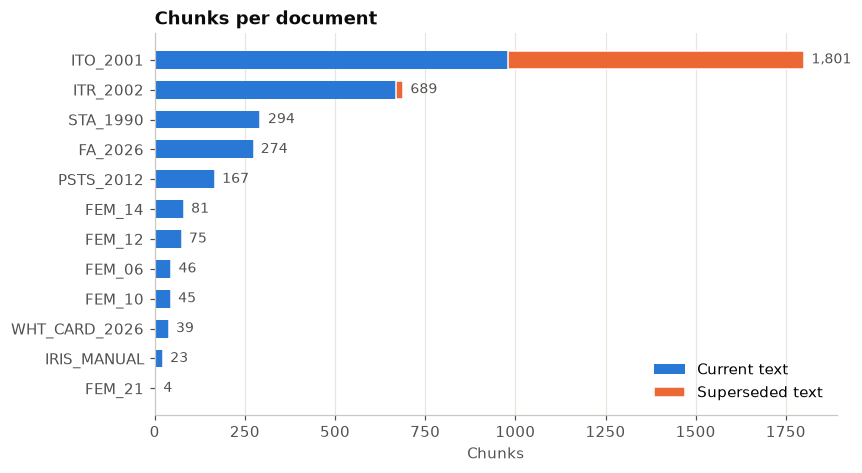

In [7]:
order = per_source.sort_values("chunks").index
current = df[~df["superseded"]].groupby("source").size().reindex(order, fill_value=0)
old = df[df["superseded"]].groupby("source").size().reindex(order, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order, current, color=BLUE, label="Current text", height=0.6)
ax.barh(order, old, left=current, color=ORANGE, label="Superseded text", height=0.6, edgecolor="white", linewidth=1)
for y, total in enumerate(current + old):
    ax.text(total + 20, y, f"{total:,}", va="center", color=MUTED, fontsize=9)
ax.set(title="Chunks per document", xlabel="Chunks")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
fig.savefig(IMAGES / "chunks_per_source.png")
plt.show()

**What it shows.** The corpus is heavily imbalanced. The Income Tax Ordinance alone is about half of all chunks, and with the Income Tax Rules it is about 70%. Chapter 21 of the Foreign Exchange Manual is 4 chunks. Almost all superseded text comes from the Ordinance, because it is the only document whose footnotes quote the old wording in full.

### 3.2 How long are the chunks?

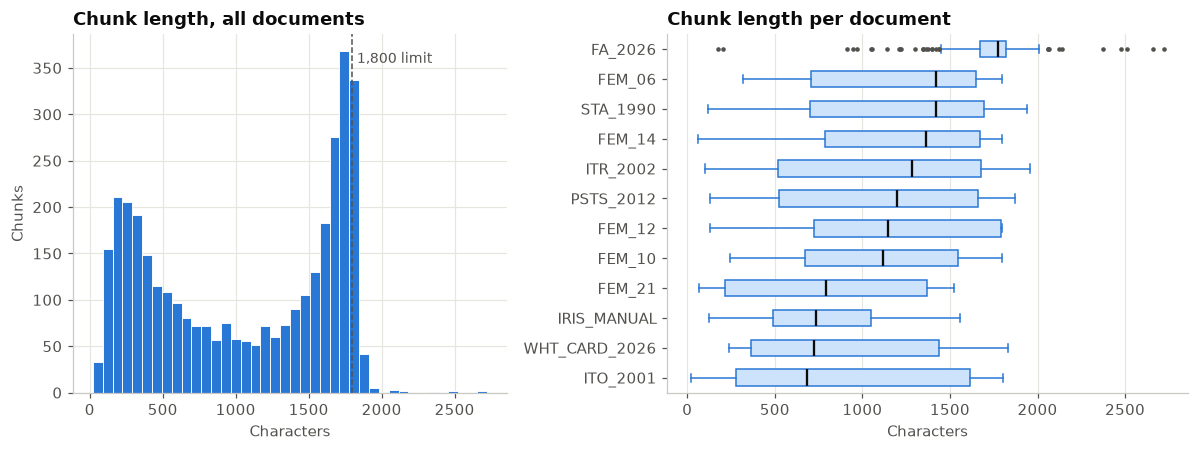

In [8]:
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})
a.hist(df["chars"], bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
a.axvline(1800, color=MUTED, linestyle="--", linewidth=1)
a.text(1830, a.get_ylim()[1] * 0.92, "1,800 limit", color=MUTED, fontsize=9)
a.set(title="Chunk length, all documents", xlabel="Characters", ylabel="Chunks")

by_median = df.groupby("source")["chars"].median().sort_values().index
b.boxplot([df.loc[df["source"] == s, "chars"] for s in by_median], orientation="horizontal", tick_labels=by_median, widths=0.55,
          patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=INK, linewidth=1.5),
          whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
          flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none"))
b.set(title="Chunk length per document", xlabel="Characters")
b.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMAGES / "chunk_length.png")
plt.show()

**What it shows.** Length has two groups rather than one bell shape: many short chunks (short sections, definitions and superseded clauses) and a second group pushed up against the 1,800-character limit (long sections that were split). The Income Tax Ordinance has the lowest median because its superseded clauses are short. The Finance Act goes past the limit because its chunks are mostly tables, which carry a repeated header.

### 3.3 When was the law amended?

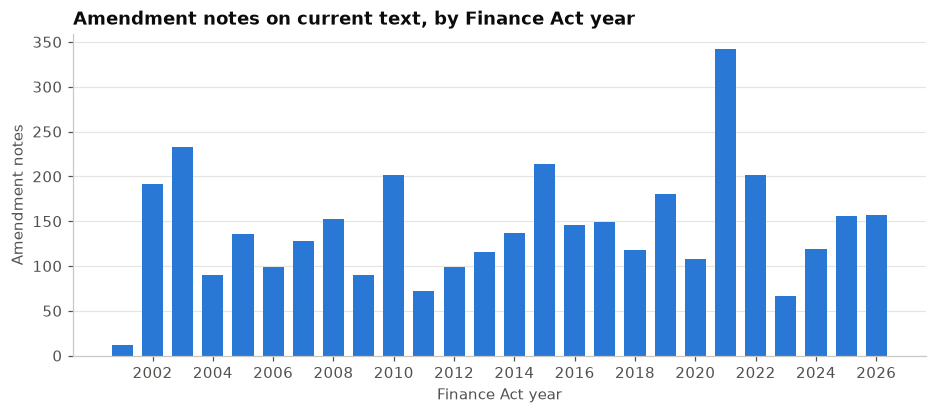

4,685 amendment notes; 3,797 name a Finance Act or Finance Ordinance year
Busiest years: {2021: 342, 2003: 233, 2015: 214}


In [9]:
notes = df.loc[~df["superseded"], "amendments"].explode().dropna()
year = notes.str.extract(r"Finance (?:Act|Ordinance),? (\d{4})")[0].dropna().astype(int)
by_year = year[year >= 2001].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(by_year.index, by_year.values, color=BLUE, width=0.7)
ax.set(title="Amendment notes on current text, by Finance Act year", xlabel="Finance Act year", ylabel="Amendment notes")
ax.set_xticks(range(2002, 2027, 2))
ax.grid(axis="x", visible=False)
fig.savefig(IMAGES / "amendments_by_year.png")
plt.show()
print(f"{len(notes):,} amendment notes; {len(year):,} name a Finance Act or Finance Ordinance year")
print("Busiest years:", by_year.sort_values(ascending=False).head(3).to_dict())

**What it shows.** The law changes every year, not occasionally, and some Finance Acts rewrite far more than others (2021 stands out). A system that only knows today's text would answer questions about past tax years wrongly, which is the reason the project tracks dates at all.

### 3.4 How much history can the system answer about?

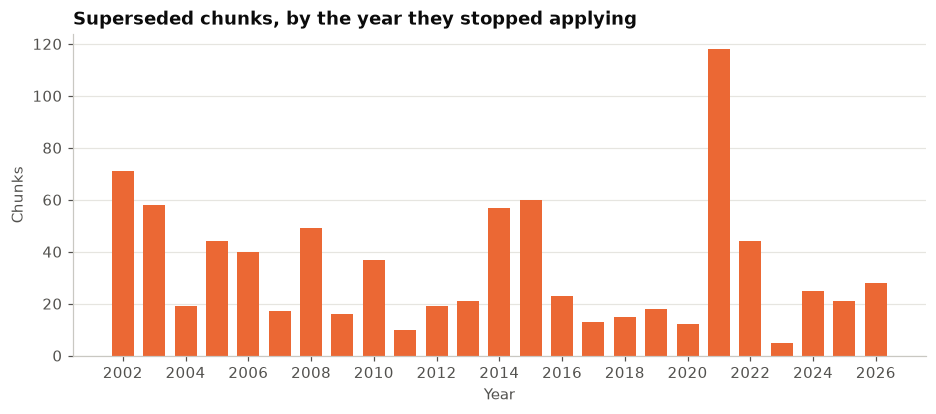

840 superseded chunks = 23.7% of the corpus
By document: {'ITO_2001': 820, 'ITR_2002': 19, 'STA_1990': 1}


In [10]:
ended = pd.to_datetime(df["effective_to"].dropna()).dt.year.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(ended.index, ended.values, color=ORANGE, width=0.7)
ax.set(title="Superseded chunks, by the year they stopped applying", xlabel="Year", ylabel="Chunks")
ax.set_xticks(range(2002, 2027, 2))
ax.grid(axis="x", visible=False)
fig.savefig(IMAGES / "superseded_by_year.png")
plt.show()
print(f"{int(df['superseded'].sum()):,} superseded chunks = {100 * df['superseded'].mean():.1f}% of the corpus")
print("By document:", df[df["superseded"]].groupby("source").size().to_dict())

**What it shows.** About a quarter of the corpus is old wording, spread over every year from 2002 to 2026, so "as of" questions have material to retrieve for any past year. Coverage is uneven: it is deep for the Income Tax Ordinance and close to empty for the Sales Tax Act and the provincial act.

### 3.5 The evaluation set

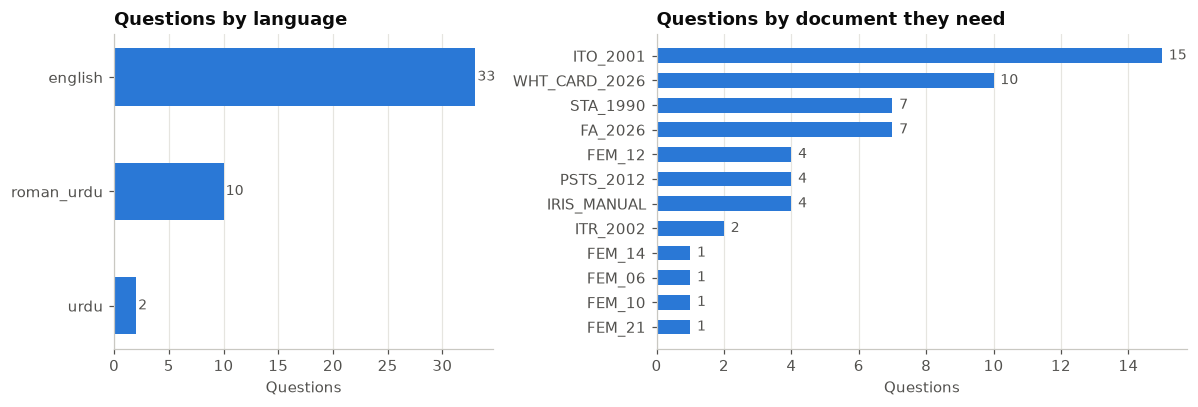

45 questions; 1 ask about a past date


In [11]:
ev = pd.read_json(ROOT / "eval/codeswitch_eval_set.jsonl", lines=True)
lang = ev["language"].value_counts().sort_values()
src = ev["sources"].explode().value_counts().sort_values()

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
a.barh(lang.index, lang.values, color=BLUE, height=0.5)
a.set(title="Questions by language", xlabel="Questions")
b.barh(src.index, src.values, color=BLUE, height=0.6)
b.set(title="Questions by document they need", xlabel="Questions")
for ax in (a, b):
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(ax.patches):
        ax.text(v.get_width() + 0.2, y, int(v.get_width()), va="center", color=MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(IMAGES / "eval_set.png")
plt.show()
print(len(ev), "questions;", int(ev["as_of"].notna().sum()), "ask about a past date")

**What it shows.** The evaluation set is small and mostly English; Urdu script has only 2 questions, so scores for Urdu will not be reliable on their own. Every document is covered at least once. The rate card is tested far more than its size suggests (39 chunks, 10 questions), which is deliberate: rate questions are what users ask most.

## 4. Preprocessing for modeling

| Step | Where | Why |
|---|---|---|
| Chunk at section boundaries, at most 1,800 characters | `ingestion/parse.py` | keeps each chunk about one legal idea and inside the embedding model's input size |
| Content-hash ids | `ingestion/parse.py` | re-indexing only embeds chunks whose text changed |
| Embed `content` to a 768-dimension vector | `indexing/index.py` | semantic search across English, Urdu and Roman Urdu questions |
| Full-text index (`tsvector`) on the same text | `db/schema.sql` | exact matches for section numbers and rates such as `154A` or `0.25%` |
| Date range on every chunk | `effective_from`, `effective_to` | filters retrieval to the law in force on the date asked about |

**Normalization and scaling.** There are no numeric features to scale. The equivalent step for text is done by the embedding model, and similarity is measured by cosine distance, which ignores vector length. Text is deliberately **not** lowercased, stemmed or stripped of punctuation before embedding: in a statute, `154A` and `154` are different sections and `shall` and `may` carry different legal meaning.

## 5. Findings

1. **The corpus is clean where it matters.** No missing text, sections, pages or dates; unique ids; consistent formats; no encoding damage.
2. **It is very imbalanced.** One document is half the corpus and two are 70%. Small documents can be crowded out in retrieval, so results need to be checked per document, not only overall.
3. **Chunk length has two groups**, short clauses and chunks at the 1,800 limit. Short superseded clauses carry little context on their own, so the section heading has to travel with them.
4. **Amendments are constant and uneven**, with 2021 the heaviest year. Date filtering is a requirement, not an extra.
5. **History is deep for income tax and thin elsewhere.** "As of" answers outside the Income Tax Ordinance will mostly fall back to current text.
6. **The evaluation set is small and English-heavy.** Urdu-script results need more questions before they mean anything.

### Known issues carried into Phase 2

- 2 superseded fragments under 50 characters.
- 2 superseded passages stored twice with different end dates.